# UCSF external test

This is the one-time evaluation of the locked models on the UCSF test set. The predictions in `results/ucsf_predictions.csv` were made by `src/score_ucsf.py`, which never loads labels. **Labels are loaded here for the first time.**

**Analysis Plan**:
- Models: age-only, image v2 and fused. Each score is the mean of the probabilities of its five fold models (trained on UTSW only).
- Cutoff for 0/1: since the models were trained using the UTSW mutant rate and we are assuming UCSF is entirely external, the UTSW mutant rate will be used (175/617 = 0.284), not UCSF's own rate. No recalibration.
- Primary metric: AUROC with a patient-level bootstrap 95% CI (1000 resamples, seed 42).
- Tested comparisons (improvement = paired 95% CI excludes 0): fused minus age-only and image v2 minus age-only. Everything else is exploratory and labeled so.

## Setup and Join Labels
Load the helpers and fix the cutoff from the UTSW training labels. `MODELS` maps each model to its column in the predictions file. Additionally, the predictions file has no labels, so this is where they come in. The checks make sure every UCSF patient is scored exactly once.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_curve, roc_auc_score, roc_curve)

from src.cohort import build_cohort
from src.config import CMP_PATH, OOF_PATH, RESULTS
from src.metrics import bootstrap_ci, paired_auroc_difference, paired_difference, summarize

MODELS = {"age_only": "age_only_prob", "image_v2": "image_v2_prob", "fused": "fused_prob"}
PRED_PATH = RESULTS / "ucsf_predictions.csv"

# The cutoff comes from UTSW labels only; UCSF's own mutant rate is never used for it
CUTOFF = build_cohort(expected_n=617, verbose=False)["idh"].mean()
assert abs(CUTOFF - 175 / 617) < 1e-9
print(f"cutoff (UTSW mutant rate): {CUTOFF:.4f}")

cutoff (UTSW mutant rate): 0.2836


In [2]:
# join labels 
ucsf = build_cohort(dataset="ucsf", expected_n=495, verbose=False)     # labels are loaded here
pred = pd.read_csv(PRED_PATH)
assert len(pred) == 495 and pred["patient_id"].is_unique
assert set(pred["patient_id"]) == set(ucsf["patient_id"])
data = ucsf[["patient_id", "idh", "age"]].merge(pred[["patient_id", *MODELS.values()]],
                                                on="patient_id", validate="one_to_one")
assert len(data) == 495 and data[list(MODELS.values())].notna().all().all()

y = data["idh"].to_numpy()
probs = {name: data[col].to_numpy() for name, col in MODELS.items()}
prevalence = y.mean()
assert (int(y.sum()), int((1 - y).sum())) == (103, 392), "label counts differ from notebook 01"
print(f"{len(y)} patients | {int(y.sum())} mutant, {int((1 - y).sum())} wildtype | prevalence {prevalence:.3f}")
print(f"references: PR-AUC {prevalence:.3f} | Brier of always predicting prevalence {prevalence * (1 - prevalence):.3f}")

495 patients | 103 mutant, 392 wildtype | prevalence 0.208
references: PR-AUC 0.208 | Brier of always predicting prevalence 0.165


## Primary result
AUROC is the headline instead of PR-AUC because it does not depend on prevalence (UTSW is 28% mutant, UCSF 21%). Precision depends on prevalence, so it is expected to be lower here even for an equally good ranking. The 0/1 columns use the fixed UTSW cutoff. `mean_predicted` next to the observed prevalence is a quick check of overall calibration.

In [3]:
rows = []
for name, prob in probs.items():
    call = (prob >= CUTOFF).astype(int)           # same cutoff for every model and patient
    row = {"model": name, **summarize(y, prob, call), "mean_predicted": prob.mean(), "n_called_mutant": int(call.sum())}
    row["auroc_ci_low"], row["auroc_ci_high"] = bootstrap_ci(y, prob, roc_auc_score)
    row["pr_auc_ci_low"], row["pr_auc_ci_high"] = bootstrap_ci(y, prob, average_precision_score)
    rows.append(row)
results = pd.DataFrame(rows).set_index("model")

headline = pd.DataFrame({
    "AUROC (95% CI)": [f"{r.auroc:.3f} ({r.auroc_ci_low:.3f} to {r.auroc_ci_high:.3f})" for r in results.itertuples()],
    "PR-AUC (95% CI)": [f"{r.pr_auc:.3f} ({r.pr_auc_ci_low:.3f} to {r.pr_auc_ci_high:.3f})" for r in results.itertuples()],
}, index=results.index)
display(headline)
display(results[["brier", "accuracy", "precision", "recall", "specificity", "mean_predicted", "n_called_mutant"]].round(3))
print(f"prevalence {prevalence:.3f} (PR-AUC baseline) | Brier reference {prevalence * (1 - prevalence):.3f}")

,AUROC (95% CI),PR-AUC (95% CI)
model,,
age_only,0.905 (0.870 to 0.935),0.728 (0.638 to 0.825)
image_v2,0.919 (0.885 to 0.952),0.749 (0.658 to 0.853)
fused,0.940 (0.905 to 0.969),0.878 (0.825 to 0.927)


,brier,accuracy,precision,recall,specificity,mean_predicted,n_called_mutant
model,,,,,,,
age_only,0.093,0.840,0.579,0.854,0.837,0.253,152
image_v2,0.098,0.764,0.466,0.922,0.722,0.315,204
fused,0.074,0.822,0.543,0.922,0.796,0.278,175


prevalence 0.208 (PR-AUC baseline) | Brier reference 0.165


### Curves, confusion matrices and calibration
ROC and precision-recall curves for the three models, then one confusion matrix per model at the UTSW cutoff (rows = true, columns = predicted). Calibration with 5 equal-count bins, the same method as the UTSW notebooks. The dashed line is each model's UTSW out-of-fold curve, for reference (single models there, 5-model averages on UCSF). No recalibration was applied, so any shift is reported as it comes out. A lower UCSF prevalence is expected to pull observed rates below predicted ones.

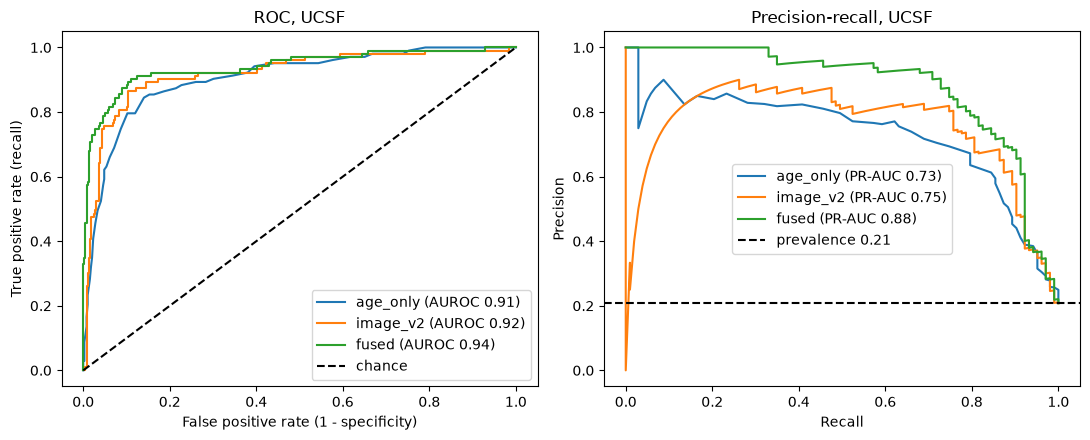

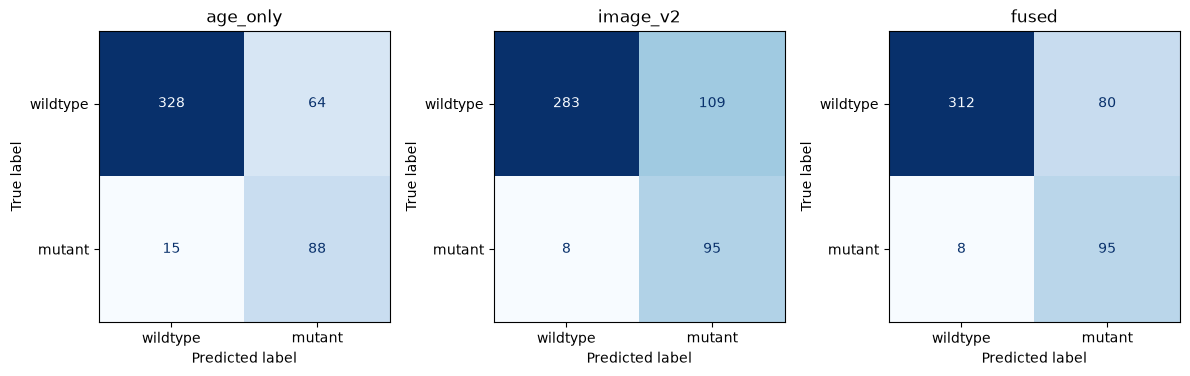

In [4]:
# ROC and precision-recall curves 
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name, prob in probs.items():
    fpr, tpr, _ = roc_curve(y, prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUROC {roc_auc_score(y, prob):.2f})")
    prec, rec, _ = precision_recall_curve(y, prob)
    axes[1].plot(rec, prec, label=f"{name} (PR-AUC {average_precision_score(y, prob):.2f})")
axes[0].plot([0, 1], [0, 1], "k--", label="chance")
axes[0].set(xlabel="False positive rate (1 - specificity)", ylabel="True positive rate (recall)", title="ROC, UCSF")
axes[1].axhline(prevalence, color="k", ls="--", label=f"prevalence {prevalence:.2f}")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall, UCSF")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

# Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (name, prob) in zip(axes, probs.items()):
    ConfusionMatrixDisplay(confusion_matrix(y, (prob >= CUTOFF).astype(int)),
                           display_labels=["wildtype", "mutant"]).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

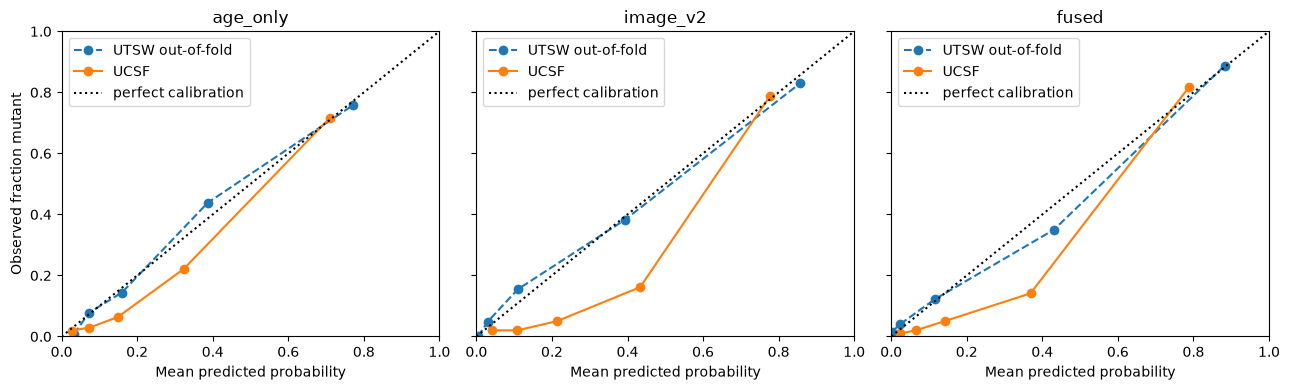

In [5]:
# Calibration Curves
oof = pd.read_csv(OOF_PATH)
utsw_cols = {"age_only": "clinical_age_prob", "image_v2": "image_cnn_v2_prob", "fused": "fused_cnn_prob"}
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
for ax, (name, prob) in zip(axes, probs.items()):
    for label, yy, pp, style in [("UTSW out-of-fold", oof["idh"].to_numpy(), oof[utsw_cols[name]].to_numpy(), "--o"),
                                 ("UCSF", y, prob, "-o")]:
        observed, predicted = calibration_curve(yy, pp, n_bins=5, strategy="quantile")
        ax.plot(predicted, observed, style, label=label)
    ax.plot([0, 1], [0, 1], "k:", label="perfect calibration")
    ax.set(xlabel="Mean predicted probability", title=name, xlim=(0, 1), ylim=(0, 1))
    ax.legend(loc="upper left")
axes[0].set_ylabel("Observed fraction mutant")
plt.tight_layout()
plt.show()

## Primary Tested Comparisons
Paired patient-level bootstrap of the AUROC difference: both models are scored on the same resampled patients in every draw. A model counts as an improvement only if the whole 95% interval is above 0. The two primary comparisons is fused vs age AUROC and image v2 vs age AUROC. 

In [6]:
def verdict(lo, hi):
    return "improvement" if lo > 0 else ("worse" if hi < 0 else "not distinguishable")

rows = []
for a, b in [("fused", "age_only"), ("image_v2", "age_only")]:
    diff, (lo, hi) = paired_auroc_difference(y, probs[a], probs[b])
    rows.append({"comparison": f"{a} minus {b}", "AUROC difference": diff, "95% CI low": lo, "95% CI high": hi,
                 "result": verdict(lo, hi)})
display(pd.DataFrame(rows).set_index("comparison").round(3))

,AUROC difference,95% CI low,95% CI high,result
comparison,,,,
fused minus age_only,0.035,0.003,0.069,improvement
image_v2 minus age_only,0.014,-0.023,0.053,not distinguishable


## Exploratory results
Not primary, no multiplicity correction, so these describe and do not test. Paired PR-AUC and Brier differences (a negative Brier difference means better), plus fused against image v2. The exploratory summary table below also includes the primary test comparison above. 

In [7]:
rows = []
for a, b in [("fused", "age_only"), ("image_v2", "age_only"), ("fused", "image_v2")]:
    for metric_name, metric in [("AUROC", roc_auc_score), ("PR-AUC", average_precision_score), ("Brier", brier_score_loss)]:
        diff, (lo, hi) = paired_difference(y, probs[a], probs[b], metric)
        rows.append({"comparison": f"{a} minus {b}", "metric": metric_name, "difference": diff, "95% CI low": lo, "95% CI high": hi})
display(pd.DataFrame(rows).set_index(["comparison", "metric"]).round(3))

difference  95% CI low  95% CI high
comparison              metric                                     
fused minus age_only    AUROC        0.035       0.003        0.069
                        PR-AUC       0.150       0.069        0.225
                        Brier       -0.018      -0.033       -0.004
image_v2 minus age_only AUROC        0.014      -0.023        0.053
                        PR-AUC       0.021      -0.091        0.134
                        Brier        0.005      -0.012        0.023
fused minus image_v2    AUROC        0.021       0.009        0.033
                        PR-AUC       0.130       0.051        0.192
                        Brier       -0.024      -0.029       -0.019

### UTSW and UCSF Results Comparison
The UTSW training set is compared to the UCSF external test set. UTSW rows are the development estimates from cross-validation (single models, settings tuned on those patients). UCSF rows are 5-model averages on a new institution. 

In [8]:
cmp = pd.read_csv(CMP_PATH).set_index("model")
utsw_names = {"age_only": "clinical_age", "image_v2": "image_cnn_v2", "fused": "fused_cnn"}
def fmt(r, lo="auroc_ci_low", hi="auroc_ci_high", val="auroc"):
    return f"{r[val]:.3f} ({r[lo]:.3f} to {r[hi]:.3f})"
side = pd.DataFrame({
    "UTSW AUROC (out-of-fold)": [fmt(cmp.loc[utsw_names[m]]) for m in MODELS],
    "UCSF AUROC": [fmt(results.loc[m]) for m in MODELS],
    "UTSW PR-AUC": [fmt(cmp.loc[utsw_names[m]], "pr_auc_ci_low", "pr_auc_ci_high", "pr_auc") for m in MODELS],
    "UCSF PR-AUC": [fmt(results.loc[m], "pr_auc_ci_low", "pr_auc_ci_high", "pr_auc") for m in MODELS],
}, index=list(MODELS))
display(side)

,UTSW AUROC (out-of-fold),UCSF AUROC,UTSW PR-AUC,UCSF PR-AUC
age_only,0.880 (0.853 to 0.909),0.905 (0.870 to 0.935),0.687 (0.616 to 0.768),0.728 (0.638 to 0.825)
image_v2,0.907 (0.880 to 0.930),0.919 (0.885 to 0.952),0.822 (0.768 to 0.867),0.749 (0.658 to 0.853)
fused,0.922 (0.894 to 0.947),0.940 (0.905 to 0.969),0.861 (0.812 to 0.902),0.878 (0.825 to 0.927)


### Age-band Analysis (exploratory)
Like what has been done in the UTSW model analysis notebooks, an age-band analysis was done on the UCSF test set as well. The same bands from the UTSW notebooks were used here: up to 50, 51 to 65, 66 and over. AUROC is estimated only with at least 20 mutants and 20 wildtype in the band, the same rule as the subgroup report. Intervals are unpaired.

In [9]:
MIN_PER_CLASS = 20
band = pd.cut(data["age"], [0, 50, 65, 200], labels=["up to 50", "51 to 65", "66 and over"])
rows = []
for b in band.cat.categories:
    m = (band == b).to_numpy()
    n_mut, n_wt = int(y[m].sum()), int((1 - y[m]).sum())
    row = {"age band": b, "patients": int(m.sum()), "mutant": n_mut, "wildtype": n_wt}
    for name, prob in probs.items():
        if min(n_mut, n_wt) >= MIN_PER_CLASS:
            lo, hi = bootstrap_ci(y[m], prob[m], roc_auc_score)
            row[name] = f"{roc_auc_score(y[m], prob[m]):.2f} ({lo:.2f} to {hi:.2f})"
        else:
            row[name] = "not estimated"
    rows.append(row)
display(pd.DataFrame(rows).set_index("age band"))

,patients,mutant,wildtype,age_only,image_v2,fused
age band,,,,,,
up to 50,152,88,64,0.76 (0.68 to 0.84),0.92 (0.87 to 0.96),0.94 (0.89 to 0.97)
51 to 65,190,12,178,not estimated,not estimated,not estimated
66 and over,153,3,150,not estimated,not estimated,not estimated


## Takeaways
**Summary:** Ranking transferred to the external set; the fixed UTSW cutoff and the probabilities did not. The fused model is best, but its gain over age alone is modest.

**Tested comparisons (primary; improvement = paired 95% CI excludes 0)**
- Fused minus age-only AUROC: +0.035 (0.003 to 0.069). Meets the rule, but the lower bound is close to 0, so the gain is modest. On UTSW it was +0.042 (0.009 to 0.071).
- Image v2 minus age-only AUROC: +0.014 (-0.023 to 0.053). Does not meet the rule, so the images alone are not shown to beat age. Same on UTSW.

**Exploratory (not pre-specified, no multiplicity correction)**
- Fused minus age-only: PR-AUC +0.150 (0.069 to 0.225) and Brier -0.018 (-0.033 to -0.004), both intervals exclude 0. Image v2 minus age-only: no interval excludes 0 for AUROC, PR-AUC or Brier.
- Fused minus image v2: intervals exclude 0 for AUROC (+0.021), PR-AUC (+0.130) and Brier (-0.024). On UTSW the AUROC difference was +0.015 (-0.004 to 0.033).

**UTSW vs UCSF**
- UCSF AUROC (0.905 to 0.940) is at or above the UTSW out-of-fold estimates (0.880 to 0.922), with overlapping intervals and no test between them. This shows no sign of a drop in ranking. It is not evidence of better generalization: age-only is also higher on UCSF, so UCSF may simply be easier. The differences between models (paired) transfer better than the absolute levels.
- PR-AUC is shown but the comparison between dataset is not taken seriously because its baseline is the prevalence (0.284 vs 0.208).

**Age bands (exploratory, unpaired intervals)**
- Only the up-to-50 band had enough patients (88 mutant, 64 wildtype). Age-only 0.76 (0.68 to 0.84) vs image v2 0.92 (0.87 to 0.96) and fused 0.94 (0.89 to 0.97). Where age separates the groups poorly, the image models still rank well, so the images carry information beyond age. This does not say what that information is, and it does not rule out age-related appearance inside the band. The other bands (12 and 3 mutants) could not be estimated.

**Cutoff, false positives and calibration (no recalibration applied)**
- At the UTSW cutoff (0.284) the models call 152, 204 and 175 patients mutant against 103 true, so precision falls (age-only 0.58, image v2 0.47, fused 0.54) while recall is high (0.85, 0.92, 0.92). Lower prevalence accounts for most of this for age-only and fused; image v2 has more false positives than prevalence alone predicts (specificity 0.848 on UTSW, 0.722 on UCSF), which points to a shift in its scores.
- The calibration curves lie below the diagonal in the lower and middle ranges for all three models, most clearly for image v2: the models over-predict mutant probability on UCSF. The top bin is close to the diagonal and Brier is still better than the always-prevalence reference (0.165) for all three models. Bins hold about 99 patients each, so low-bin rates rest on few events, but the direction is consistent across models. The cause (prevalence, patient mix, scanner, segmentation tool) cannot be separated here.

**Limits:** one institution and 495 patients, so this is not clinical validation; UTSW scores are development estimates (the image-only settings were tuned on those patients); UCSF scores are 5-model averages while UTSW scores are single models; the intervals cover patient sampling only, not retraining variability; one UCSF patient is 17 years old; the cutoff comes from UTSW and no recalibration was applied; the tumor segmentations come from different tools (FeTS for UTSW, mix of automated (BraTS) and manual segmentation for UCSF), and a few large UCSF tumors are partly cut off at the crop edge (worst keeps 88.4%).

## Save the headline table
One small table for the write-up: the three UCSF rows, same columns as `model_comparison.csv`. Delete this cell if you would rather not keep it in the repo.

In [10]:
out = results.reset_index()
out.insert(1, "n_patients", len(y))
out.round(3).to_csv(RESULTS / "ucsf_model_comparison.csv", index=False)